# 01 - Preparing spectra with py4radiation

This tutorial shows how to load, scale, compare and prepare custom spectral energy distributions (SEDs) for Cloudy.

We consider two reference models:

- Starburst99 stellar continua (Leitherer et al. 1999).
- The Haardt & Madau (2012) UV/X-ray background at $z=0$ (HM2012).

`py4radiation` retrieves the tabulated spectra, applies the relevant physical scaling, and prepares the results for `pyCIAO`/Cloudy.

## Objectives

1. Load a continuous star-formation spectrum from Starburst99.
2. Examine the effects of star-formation rate and distance.
3. Compare the stellar spectrum with HM2012.
4. Verify the spectral normalisation.
5. Write `pyCIAO`/Cloudy-compatible input files.

In [1]:
# Import libraries
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from py4radiation import SED

## 1. Physical conventions

FOr stellar radiation, Starburst99 presents tabulated spectral luminosities $L_{\lambda}$. The corresponding flux density at a distance $d$ is:

$$
F_{\nu} = \dfrac{L_{\nu}}{4\pi d^2}.
$$

The HM2012 tables instead provide the specific intensity $J_{\nu}$. For comparison with the stellar spectra, py4radiation returns

$$
F_{\nu,\mathrm{equiv}} = 4\pi J_{\nu}
$$

Both quantities have units of $\mathrm{erg\,s^{-1}\,cm^{-2}\,Hz^{-1}}$.

Here, $4\pi J_{\nu}$ is the angle-integrated intensity.

Photon energies are expressed in Rydbergs, $1\,\mathrm{Ryd} \simeq 13.606\,\mathrm{eV}$.

In [2]:
# Set these paths when using locally stored tables
# Leave them as None to use the package retrieval and cache capabilities

SB99_PATH = None
HM12_PATH = None

AGE_MYR = 3
TABLE_ID = "8b" # stellar-emission only, Salpeter IMF (M_low = 1 Msun, M_up = 100 Msun)

## 2. Starburst99 stellar spectra

We use FIgure 8b, representing continuous star formation. The reference spectrum assumes a star formation rate (SFR) of $1$ $M_{\odot}\,\mathrm{yr}^{-1}$.

For a fixed stellar population model and age, changing the SFR scales the luminosity without changing the spectral shape. We compare SFRs of 1 and 5 solar masses per year at a fixed distance of 1 kpc.

In [3]:
sed_sfr1 = SED(
    run_name="sb99_sfr1", # name for the prepared spectrum
    table_id=TABLE_ID,    # identification of the Starburst99 table
    sfr_msun_yr=1.0,      # SFR in solar masses per year
    distance_kpc=1.0,     # distance to the radiation source in kiloparsecs
    age_myr=AGE_MYR,      # age of the stellar population
    sb99_path=SB99_PATH   # path if you have a local file
)

sed_sfr5 = SED(
    run_name="sb99_sfr5",
    table_id=TABLE_ID,
    sfr_msun_yr=5.0,
    distance_kpc=1.0,
    age_myr=AGE_MYR,
    sb99_path=SB99_PATH
)

# Obtain the energy and fluxes from the prepared spectra
energy1, flux1 = sed_sfr1.get_sed()
energy5, flux5 = sed_sfr5.get_sed()

In [4]:
# Numerical verification for the SFR scaling
np.testing.assert_allclose(energy1, energy5)
np.testing.assert_allclose(flux5 / flux1, 5.0, rtol=1e-12)

delta_sfr = np.log10(flux5 / flux1)

print(f"Expected difference: {np.log10(5):.6f} dex.")
print(f"Measured difference: {np.mean(delta_sfr):.6f} dex.")

Expected difference: 0.698970 dex.
Measured difference: 0.698970 dex.


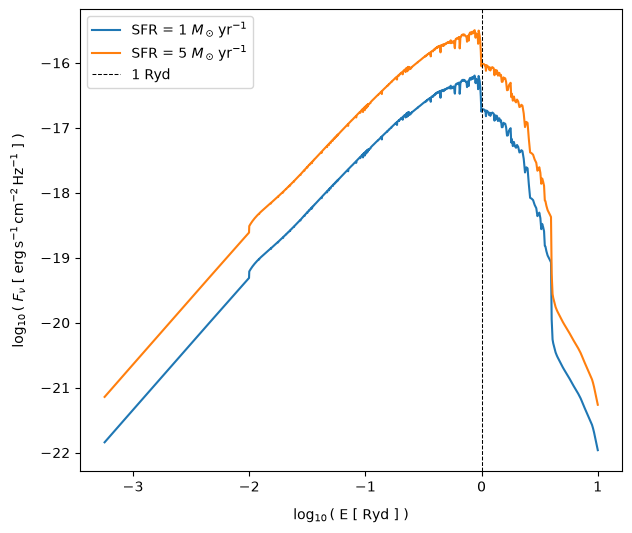

In [5]:
# Comparison between same model scaled with different SFR

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(np.log10(energy1), np.log10(flux1), label=r"SFR = 1 $M_\odot\,\mathrm{yr}^{-1}$")
ax.plot(np.log10(energy5), np.log10(flux5), label=r"SFR = 5 $M_\odot\,\mathrm{yr}^{-1}$")

ax.axvline(0.0, color="black", linewidth=0.75, linestyle="--", label="1 Ryd")

ax.set_xlabel(r"$\log_{10}$( E [ Ryd ] )", labelpad=10)
ax.set_ylabel(r"$\log_{10}$( $F_{\nu}$ [ $\mathrm{erg\,s^{-1}\,cm^{-2}\,Hz^{-1}}$ ] )", labelpad=10)

ax.legend()

plt.show()

## 3. Distance scaling

For the same stellar population, the spectral flux density decreases with the inverse square of the dsitance:

$$
F_{\nu} \propto d^{-2}.
$$

`py4radiation` heating and cooling tables consider the optically thin limit. Therefore, the geometric dilution treatment is adequate.

Moving a source from 1 kpc to 5 kpc changes its flux by a factor of 25, while the spectral shape remains unchanged.

In [6]:
sed_d5 = SED(
    run_name="sb99_d5",
    table_id=TABLE_ID,
    sfr_msun_yr=1.0,
    distance_kpc=5.0,
    age_myr=AGE_MYR,
    sb99_path=SB99_PATH
)

energy_d5, flux_d5 = sed_d5.get_sed()

np.testing.assert_allclose(energy1, energy_d5)
np.testing.assert_allclose(flux1 / flux_d5, 25.0, rtol=1e-12)

print(f"Expected difference: {np.log10(25):.6f} dex")
print(f"Measured difference: {np.mean(np.log10(flux1 / flux_d5)):.6f} dex")

Expected difference: 1.397940 dex
Measured difference: 1.397940 dex


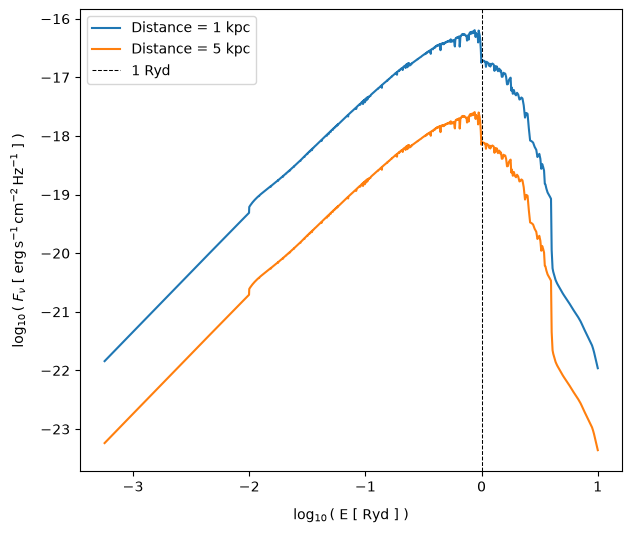

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(np.log10(energy1), np.log10(flux1), label=r"Distance = $1$ kpc")
ax.plot(np.log10(energy_d5), np.log10(flux_d5), label=r"Distance = $5$ kpc")

ax.axvline(0.0, color="black", linewidth=0.75, linestyle="--", label="1 Ryd")

ax.set_xlabel(r"$\log_{10}$( E [ Ryd ] )", labelpad=10)
ax.set_ylabel(r"$\log_{10}$( $F_{\nu}$ [ $\mathrm{erg\,s^{-1}\,cm^{-2}\,Hz^{-1}}$ ] )", labelpad=10)

ax.legend()

plt.show()

## 4. Haardt & Madau (2012)

The HM2012 model describes the metagalactic UV/X-ray background. Its tabulated quantity is the specific intensity $J_{\nu}$, not a spectral luminosity. We use the redshift-zero spectrum and convert its intensity to the angle-integrated quantity $4\pi J_{\nu}$.

No SFR, stellar mass or distance scaling is applied.

In [8]:
sed_hm12 = SED(
    run_name="hm12_z0",
    table_id="HM12",
    hm12_path=HM12_PATH
)

energy_hm12, flux_hm12 = sed_hm12.get_sed()

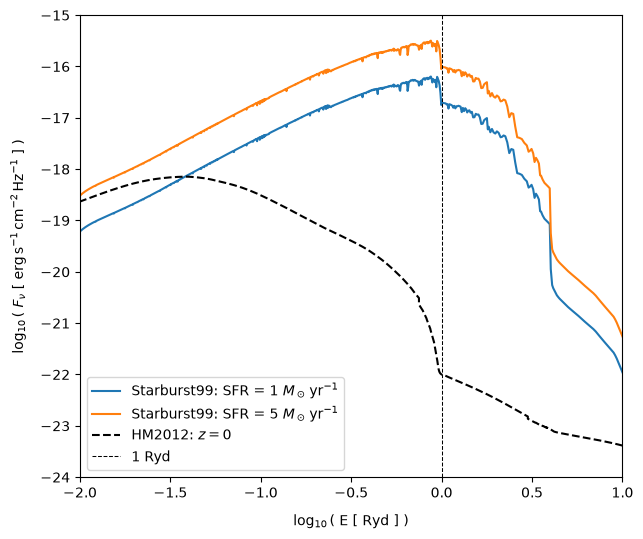

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(np.log10(energy1), np.log10(flux1), label=r"Starburst99: SFR = 1 $M_\odot\,\mathrm{yr}^{-1}$")
ax.plot(np.log10(energy5), np.log10(flux5), label=r"Starburst99: SFR = 5 $M_\odot\,\mathrm{yr}^{-1}$")

ax.plot(np.log10(energy_hm12), np.log10(flux_hm12), color="black", linestyle="--", label=r"HM2012: $z = 0$")

ax.axvline(0.0, color="black", linewidth=0.75, linestyle="--", label="1 Ryd")

ax.set_xlim(-2, 1)
ax.set_ylim(-24, -15)

ax.set_xlabel(r"$\log_{10}$( E [ Ryd ] )", labelpad=10)
ax.set_ylabel(r"$\log_{10}$( $F_{\nu}$ [ $\mathrm{erg\,s^{-1}\,cm^{-2}\,Hz^{-1}}$ ] )", labelpad=10)

ax.legend()

plt.show()

In [10]:
# py4radiation normalisation
# Cloudy needs the value of F_nu at a certain value of energy
# py4radiation chooses the value at 1 Ryd

order = np.argsort(energy_hm12)

log_fnu_at_1ryd = np.interp(0.0, np.log10(energy_hm12[order]), np.log10(flux_hm12[order]))

print(f"log10(4pi J_nu) at 1 Ryd = {log_fnu_at_1ryd:.6f}")

log10(4pi J_nu) at 1 Ryd = -22.000621


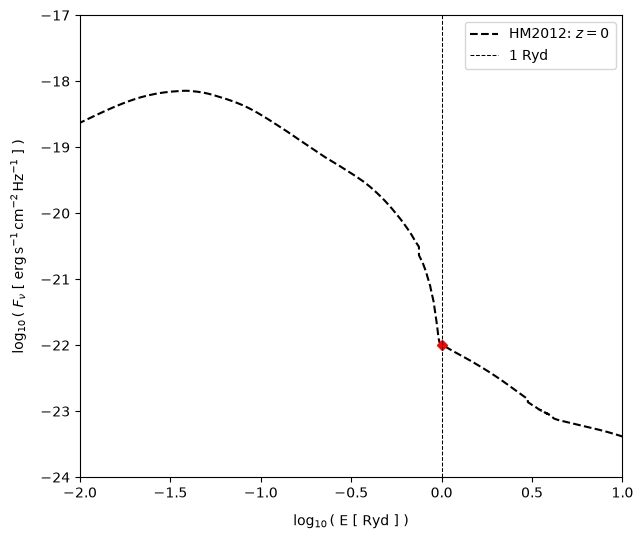

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(np.log10(energy_hm12), np.log10(flux_hm12), color="black", linestyle="--", label=r"HM2012: $z = 0$")
ax.plot(0, log_fnu_at_1ryd, color="red", marker="D", markersize=5)

ax.axvline(0.0, color="black", linewidth=0.75, linestyle="--", label="1 Ryd")

ax.set_xlim(-2, 1)
ax.set_ylim(-24, -17)

ax.set_xlabel(r"$\log_{10}$( ${\rm E}$ [ Ryd ] )", labelpad=10)
ax.set_ylabel(r"$\log_{10}$( $F_{\nu}$ [ $\mathrm{erg\,s^{-1}\,cm^{-2}\,Hz^{-1}}$ ] )", labelpad=10)

ax.legend()

plt.show()

## 5. Preparing the SEDs for Cloudy

The `write_outfile()` method converts each spectrum into Cloudy tabulated continuum syntax.

Each file contains:

- Photon energies in Rydbergs.
- The corresponding logarithmic spectral values.
- An absolute normalisation at 1 Ryd.

The files describe the incident radiation fields using for Cloudy calculations.

Writing these files does not execute Cloudy.

In [12]:
output_dir = Path("tutorial_output") / "spectra"
output_dir.mkdir(parents=True, exist_ok=True)

paths = [
    sed_sfr1.write_outfile(output_dir),
    sed_sfr5.write_outfile(output_dir),
    sed_d5.write_outfile(output_dir),
    sed_hm12.write_outfile(output_dir),
]

for path in paths:
    print(path)

tutorial_output/spectra/sb99_sfr1_z0.0000e+00.out
tutorial_output/spectra/sb99_sfr5_z0.0000e+00.out
tutorial_output/spectra/sb99_d5_z0.0000e+00.out
tutorial_output/spectra/hm12_z0_z0.0000e+00.out


The prepared spectra can now be used in photoionisation calculations!